In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from scipy.interpolate import PchipInterpolator

import os

In [2]:
# cleaned file
f_path = os.path.join(
    "..", "data", "clean",
    "launches_clean_plotting.csv"
)

data = pd.read_csv(f_path)

data.head(1)

,Date,total_payloads,Overall,USA,Europe,Asia,Other
0,1999-05-26,2,2,0,1,1,0


In [10]:
# copy only what's needed to plot

# cols for plotting
cols_plotting = [
    'Date', 'USA', 'Europe', 'Asia', 'Other'
]
df = data[cols_plotting]

df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
df["Year"] = df["Date"].dt.year

In [11]:
df.head()

,Date,USA,Europe,Asia,Other,Year
0,1999-05-26,0,1,1,0,1999
1,2001-10-22,0,3,1,0,2001
2,2007-01-10,0,3,2,1,2007
3,2007-04-23,0,4,2,1,2007
4,2008-01-21,0,4,3,1,2008


In [12]:
# facts
total = 434
usa_share = 233/434
eu_share = 139/434
asia_share = 41/434
others_share = 21/434

In [30]:
# original values
df = df.copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

x = df["Date"]

y_usa = df["USA"]
y_eu = df["Europe"]
y_asia = df["Asia"]
y_other = df["Other"]

# convert dates to numeric values (days since first date)
x_numeric = (x - x.min()).dt.total_seconds().to_numpy() / 86400

# generate 300 evenly spaced numeric dates
x_sm_numeric = np.linspace(
    x_numeric.min(),
    x_numeric.max(),
    200
)

# smoothed y values
# y_usa_sm = make_interp_spline(x_numeric, y_usa)(x_sm_numeric)
# y_eu_sm = make_interp_spline(x_numeric, y_eu)(x_sm_numeric)
# y_asia_sm = make_interp_spline(x_numeric, y_asia)(x_sm_numeric)
# y_other_sm = make_interp_spline(x_numeric, y_other)(x_sm_numeric)

y_usa_sm = PchipInterpolator(x_numeric, y_usa)(x_sm_numeric)
y_eu_sm = PchipInterpolator(x_numeric, y_eu)(x_sm_numeric)
y_asia_sm = PchipInterpolator(x_numeric, y_asia)(x_sm_numeric)
y_other_sm = PchipInterpolator(x_numeric, y_other)(x_sm_numeric)

# convert numeric dates back to datetime
x_sm = x.min() + pd.to_timedelta(x_sm_numeric, unit="D")

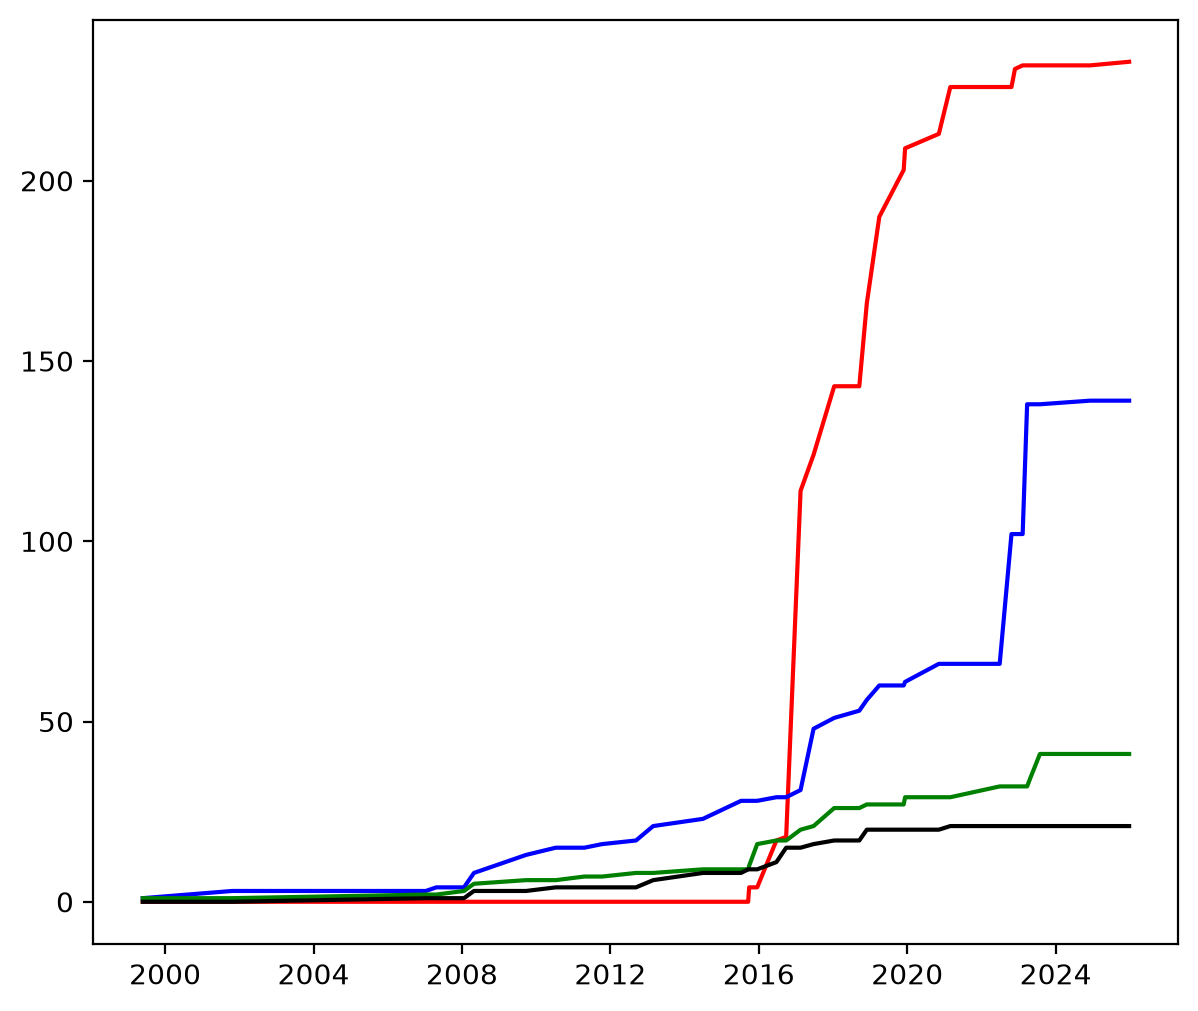

In [37]:
fig, ax = plt.subplots(figsize=(7,6), dpi=200)

ax.plot(x, y_usa, color="red")
ax.plot(x, y_eu, color="blue")
ax.plot(x, y_asia, color="green")
ax.plot(x, y_other, color="black")

plt.show()